In [43]:
import pandas as pd
import matplotlib.pyplot as plt

files = []
ft_measurements = {}

for i in range(8, 24):
    files.append(f"../measurements/{i}b_ft.txt")

for file in files:
    with open(file, "r") as f:
        bits = file.split("/")[-1].split("b")[0]
        lines = f.readlines()
        pps_l = []
        cycles_l = []
        for line in lines:
            split_line = line.split(",")

            split_pps = split_line[0].split(":")
            pps = float(split_pps[1].strip())
            
            split_cycles = split_line[1].split(":")
            cycles = float(split_cycles[1].strip())
            pps_l.append(pps)
            cycles_l.append(cycles)
        ft_measurements[bits] = {"pps": pd.Series(pps_l).median(), "cycles": pd.Series(cycles_l).median()}

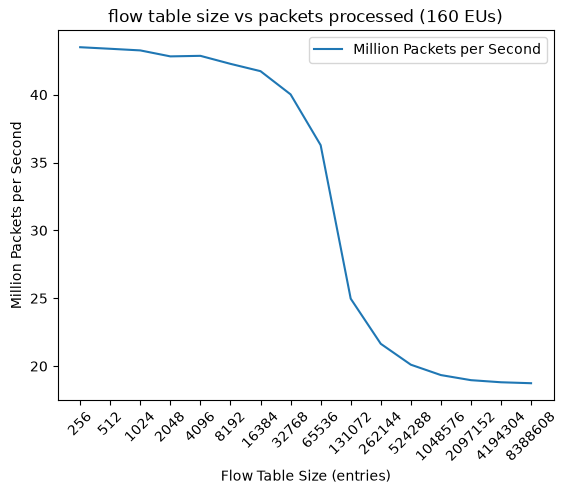

In [44]:
plt.plot([f"{pow(2, int(bits))}" for bits in ft_measurements.keys()], [ft_measurements[bits]["pps"] for bits in ft_measurements.keys()], label="Million Packets per Second")
plt.xlabel("Flow Table Size (entries)")
plt.ylabel("Million Packets per Second")
plt.xticks(rotation=45)
plt.title("flow table size vs packets processed (160 EUs)")
plt.legend()
plt.savefig("flow_table_size_vs_pps.png", bbox_inches="tight")
plt.show()

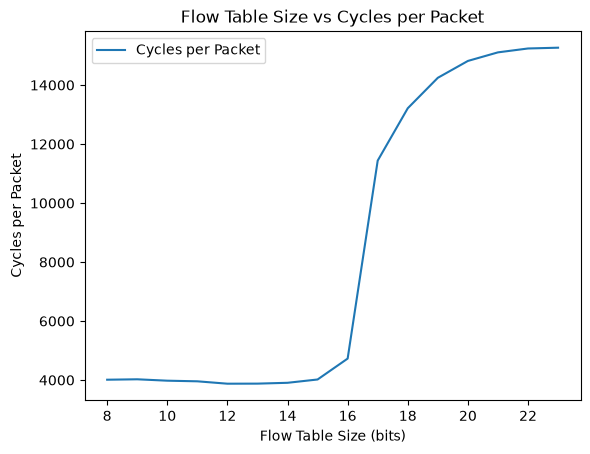

In [45]:
plt.plot([int(bits) for bits in ft_measurements.keys()], [ft_measurements[bits]["cycles"] for bits in ft_measurements.keys()], label="Cycles per Packet")
plt.xlabel("Flow Table Size (bits)")
plt.ylabel("Cycles per Packet")
plt.title("Flow Table Size vs Cycles per Packet")
plt.legend()
plt.show()